# 4. Estacionalidad y descomposición

Se representan perfiles por hora, día de semana y mes; las bandas son cuantiles empíricos, no intervalos de confianza. STL diaria aproxima el ciclo anual con 365 días. La descomposición de múltiples ciclos horarios se limita al último año completo de entrenamiento, fijado en el protocolo para acotar el coste.

El espectro de Welch usa segmentos de 365 días, frecuencia de muestreo de una observación por hora y detrending lineal. Las descomposiciones centradas observan ambos lados de cada punto dentro del entrenamiento y sólo sirven para diagnóstico. Una implementación operativa requiere filtros causales o reajustes sólo con pasado. Véase [Hyndman y Athanasopoulos](https://otexts.com/fpp3/decomposition.html).


In [1]:
%matplotlib inline
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/manifest.json').exists())
sys.path.insert(0,str(ROOT/'src'))
import pandas as pd
from IPython.display import display,Markdown
from colombia_energy import eda
pd.set_option('display.max_rows',35)
pd.set_option('display.max_columns',14)
pd.set_option('display.float_format',lambda x:f'{x:.5g}')


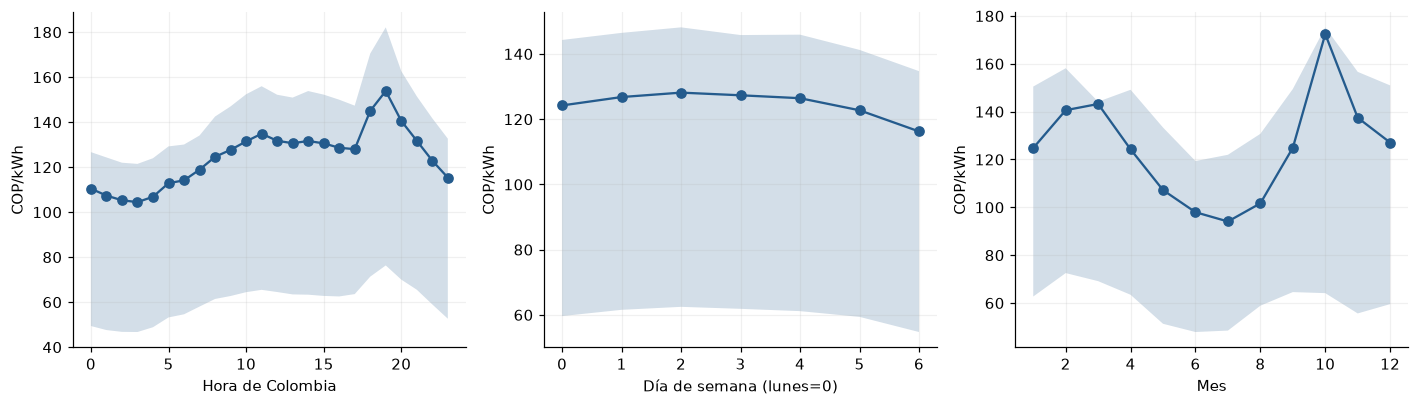

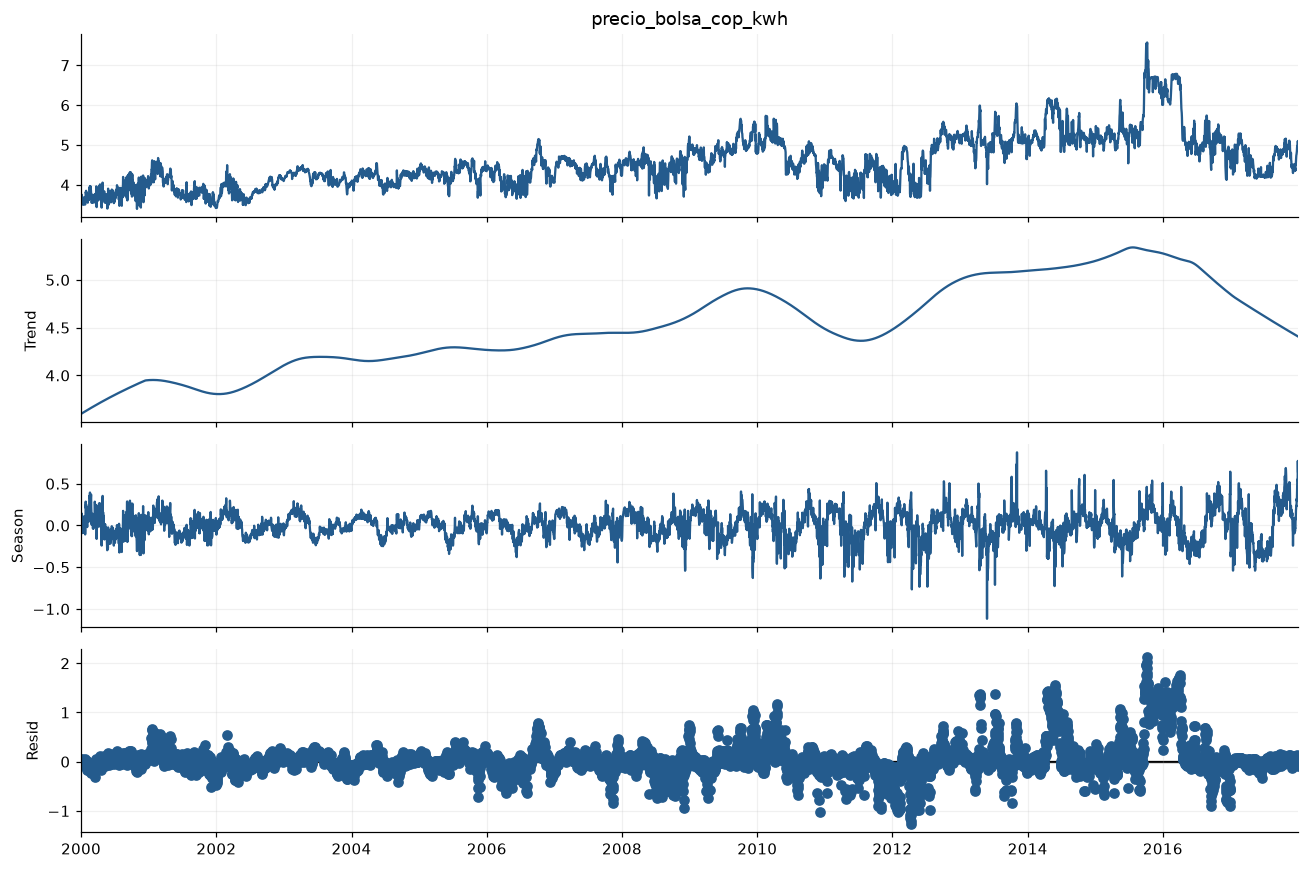

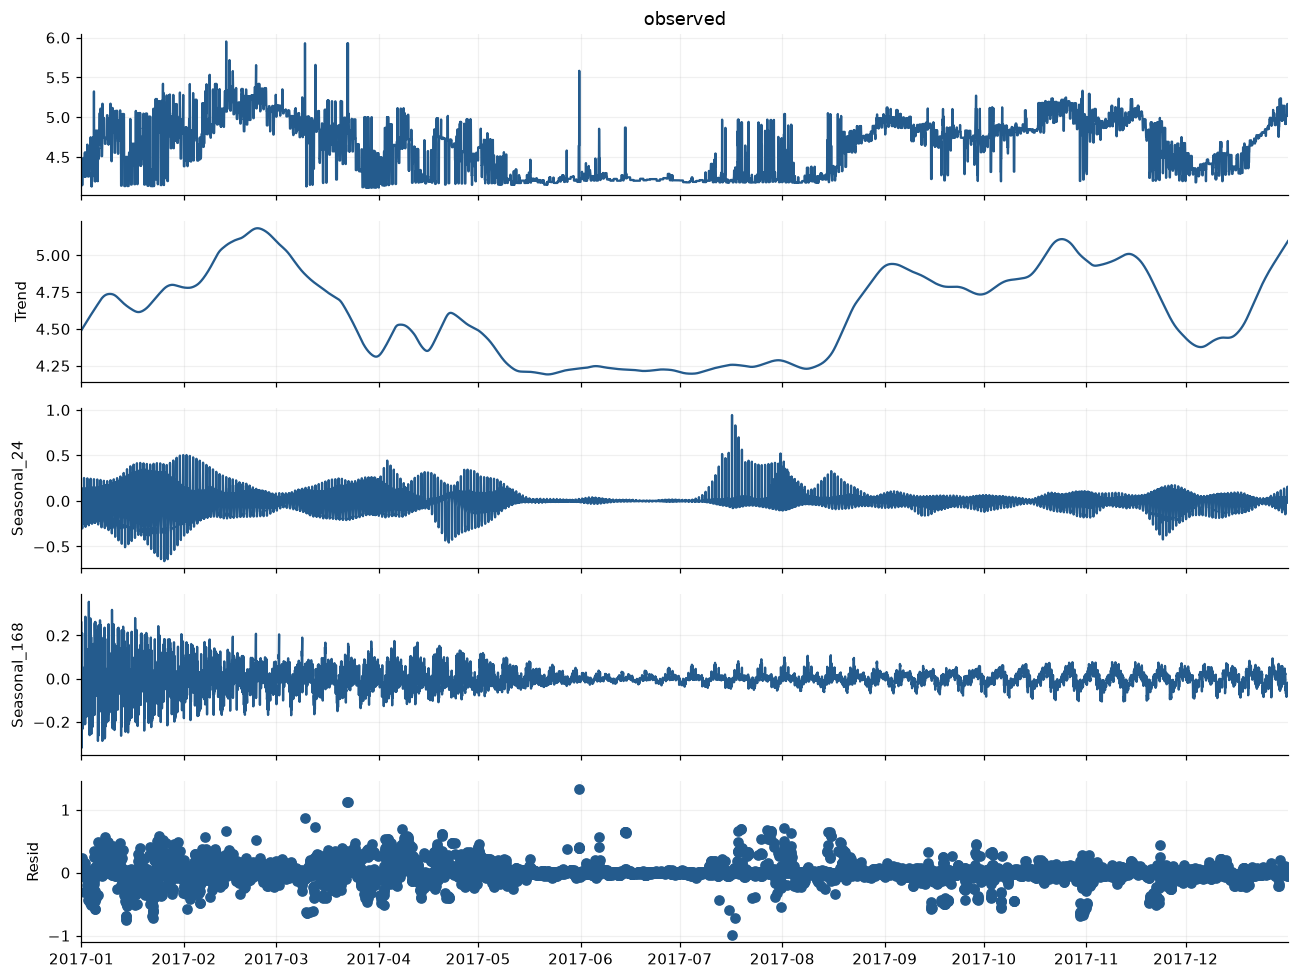

,periodo_horas,potencia
0,8760,1.2651e+07
1,4380,8.2091e+06
2,2920,6.7363e+06
3,1752,3.1855e+06
4,2190,2.3934e+06
5,1251.4,2.0197e+06
6,1095,1.6177e+06
7,1460,1.3679e+06
8,24,1.0641e+06
9,876,1.0616e+06


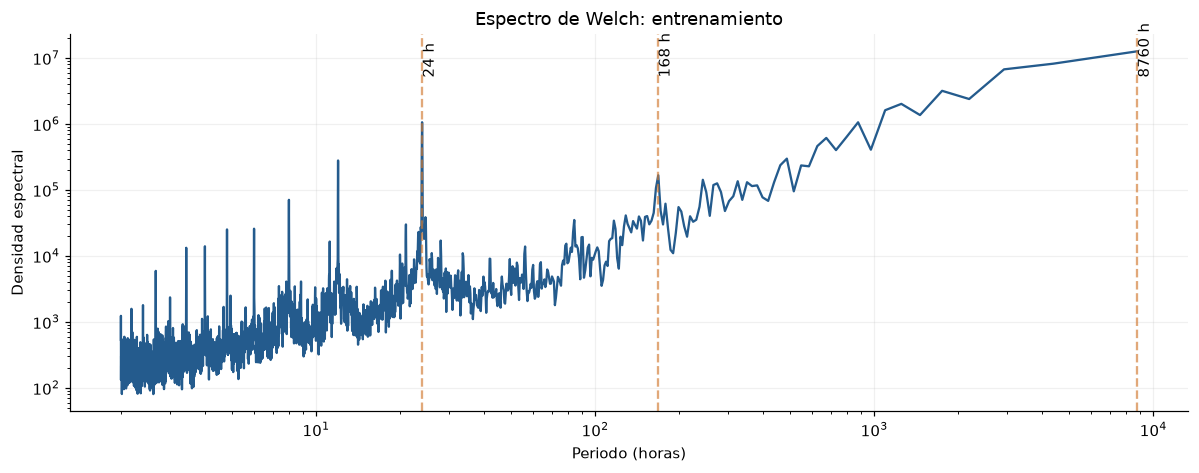

### Implicaciones del análisis

- **Preprocesamiento:** Calendario conocido al origen y rezagos diarios/semanales; el ciclo anual de 365 días aproxima años bisiestos.
- **Arquitectura:** Contexto candidato de una semana y salida de 24 horas; CNN local con acceso a rezagos estacionales o recurrencia/atención.
- **Validación:** Comparar contra ingenuos diarios y semanales con los mismos orígenes. No escoger ventanas usando prueba.
- **Riesgos:** Descomposiciones centradas son diagnóstico de train, no preprocesamiento causal listo para desplegar. Los perfiles no demuestran causalidad de hora o estación.

In [2]:
eda.seasonality()